In [ ]:
%pip install scikit-learn pandas pyarrow matplotlib -r ../../../agdata/requirements.txt

# 12-month outlook for the field: below, near or above normal

For each of the next 12 months, and for each of five variables, this notebook gives the **chance that the
month will be below, near or above normal**, and **how sure the model is**, judged by its track record.

| Code | Variable | Below / above normal means |
|---|---|---|
| `T2M` | Air temperature | cooler / warmer |
| `PRECTOTCORR` | Precipitation | drier / wetter |
| `ALLSKY_SFC_SW_DWN` | Solar radiation | duller / sunnier |
| `RH2M` | Relative humidity | drier air / more humid |
| `GWETROOT` | Root zone soil wetness | drier / wetter soil |

**Normal** is defined per grid cell and calendar month from every year since 1981. The lowest third of
past values counts as "below", the middle third as "near" and the top third as "above". Without any forecast,
each category has a 33% chance. That is the honest answer whenever the model has no proven skill, and the
outlook then says **no signal**.

**Data (via `agdata`, no credentials needed):**
- NASA POWER monthly values since 1981. Monthly values are published months late, so the latest months
  are completed from POWER's daily data.
- NASA GMAO GEOS-S2S seasonal forecasts via NOAA CPC (`ag.NMME`), from 2018-04, reaching 8 months ahead.

**Model:** one scikit-learn `HistGradientBoostingClassifier` per variable, predicting the three
probabilities directly. It is trained on all ~108 grid cells of a region around the field. Its inputs are
the last 1 and 3 months' anomalies of seven variables, the GEOS-S2S forecast, the target month, how many
months ahead, and location.

**How sure the model is:** a rolling backtest. Starting on March 1, 2010, the model is retrained every 2
years on data before that date only, then scores its forecasts for the next 2 years at every lead (1–12
months ahead). For each variable and lead it reports:
- **skill:** how much better its probabilities were than plain 33/33/33. 0 means no better; the
  measure is the ranked probability skill score.
- **hit rate:** how often the most likely category was the one that happened, versus 33% by chance.

A forecast's tilt is shown only if its skill was above 0 in **both** halves of the test, 2010–2017 and
2018–2026, and at least 0.02 overall. This rejects leads where the apparent skill flips sign between
periods. Otherwise the outlook says *no signal*.

In [1]:
import sys
import time
from pathlib import Path

import aiohttp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgba
from sklearn.ensemble import HistGradientBoostingClassifier

REPO = Path.cwd().parents[2]  # This notebook lives in Model/regressions/exploration/.
assert (REPO / 'agdata').is_dir(), f'agdata not found under {REPO}'
sys.path.insert(0, str(REPO))
import agdata as ag

## Parameters

In [2]:
# The 20 km² field, and the region pooled for training (~108 POWER cells, Iowa).
CENTER_LAT, CENTER_LON = 42.00, -93.60
BBOX = (-97.0, 40.0, -90.0, 44.0)  # (west, south, east, north); POWER regions span at most 10°

HISTORY_START = pd.Timestamp('1981-01-01')  # first year of NASA POWER weather data
TODAY = pd.Timestamp.today().normalize()
LEADS = range(1, 13)  # lead 1 = the month starting at the forecast date

# Backtest: from March 1, 2010, retrain every 2 years on earlier data only.
FIRST_FOLD, FOLD_YEARS = 2010, 2
SPLIT_YEAR = 2018  # skill must be above 0 in both halves: before and after March 1, 2018
MIN_SKILL = 0.02   # and at least this overall; otherwise the outlook says "no signal" (33/33/33)

TARGETS = {  # code: (name, units, below normal, above normal)
    'T2M': ('Air temperature', '°C', 'cooler', 'warmer'),
    'PRECTOTCORR': ('Precipitation', 'mm/day', 'drier', 'wetter'),
    'ALLSKY_SFC_SW_DWN': ('Solar radiation', 'MJ/m²/day', 'duller', 'sunnier'),
    'RH2M': ('Relative humidity', '%', 'drier air', 'more humid'),
    'GWETROOT': ('Root zone soil wetness', '0–1', 'drier', 'wetter'),
}
EXTRA = ['GWETTOP', 'GWETPROF']  # inputs only: surface and full-profile soil wetness
VARIABLES = [*TARGETS, *EXTRA]

# Neighbouring cells move together, so the data hold a few hundred independent months, not ~700k rows.
# Small trees with large leaves keep the model from memorising single years.
HGB_PARAMS = dict(max_iter=60, learning_rate=0.05, max_leaf_nodes=4, min_samples_leaf=5000,
                  l2_regularization=1.0, early_stopping=False, random_state=0)

CACHE = Path('cache')  # GEOS-S2S downloads, extended with new months on each run

## 1. Fetch data

NASA POWER is downloaded fresh on every run, which takes seconds. GEOS-S2S forecasts are cached; the first
run takes ~4 minutes, and later runs fetch only newly issued months.

In [3]:
CACHE.mkdir(exist_ok=True)
geos_file = CACHE / 'geos_s2s.parquet'
async with aiohttp.ClientSession() as http:
    power_api = ag.NasaPower(http)
    monthly = await power_api.area(BBOX, HISTORY_START, TODAY, parameters=VARIABLES, resolution='monthly')
    monthly = monthly[~monthly.time.str.endswith('13')]  # month 13 is the annual mean
    monthly['time'] = pd.to_datetime(monthly.time, format='%Y%m')

    # Monthly values lag; complete the latest months from daily data (whole months only).
    gap_start = min(monthly.dropna(subset=[v]).time.max() for v in VARIABLES) + pd.DateOffset(months=1)
    daily = await power_api.area(BBOX, gap_start, TODAY, parameters=VARIABLES, resolution='daily')
    daily['time'] = daily.time.dt.to_period('M').dt.to_timestamp()
    days = daily.groupby(['time', 'lat', 'lon'])[VARIABLES]
    counts = days.count()
    recent = days.mean().where(counts.eq(counts.index.get_level_values('time').days_in_month, axis=0))
    power = (pd.concat([monthly, recent.reset_index()])
             .groupby(['time', 'lat', 'lon']).first().reset_index())  # monthly values take precedence

    # Forecasts are made at the start of the month after the last complete month.
    ORIGIN = power.dropna(subset=['T2M']).time.max() + pd.DateOffset(months=1)
    last_issue = ORIGIN - pd.DateOffset(months=1)  # GEOS-S2S usable at ORIGIN was issued the month before
    geos = pd.read_parquet(geos_file) if geos_file.exists() else None
    first_issue = pd.Timestamp('2018-01-01') if geos is None else geos.issued.max() + pd.DateOffset(months=1)
    if first_issue <= last_issue:
        new = await ag.NMME(http).area(BBOX, first_issue, last_issue)
        print('Months without a GEOS-S2S forecast:', new.attrs['missing'])
        geos = pd.concat([geos, new], ignore_index=True)
        geos.to_parquet(geos_file)

assert (geos.issued == last_issue).any(), f'GEOS-S2S for {last_issue:%Y-%m} is not published yet'
print(f'Forecast date: {ORIGIN.date()}; GEOS-S2S issues {geos.issued.min():%Y-%m} … {geos.issued.max():%Y-%m}')

Forecast date: 2026-11-01; GEOS-S2S issues 2018-04 … 2026-10


Solar radiation comes on CERES's 1° grid (centres at x.5°), the other variables on MERRA-2's
0.5° × 0.625° grid. Each MERRA-2 cell takes the radiation of the 1° cell it falls in.

In [4]:
radiation = power.dropna(subset=['ALLSKY_SFC_SW_DWN'])[['time', 'lat', 'lon', 'ALLSKY_SFC_SW_DWN']]
power = power.dropna(subset=['T2M']).drop(columns='ALLSKY_SFC_SW_DWN')
power['rlat'] = (np.floor(power.lat) + 0.5).clip(radiation.lat.min(), radiation.lat.max())
power['rlon'] = (np.floor(power.lon) + 0.5).clip(radiation.lon.min(), radiation.lon.max())
power = (power.merge(radiation.rename(columns={'lat': 'rlat', 'lon': 'rlon'}),
                     on=['time', 'rlat', 'rlon'], how='left')
         .drop(columns=['rlat', 'rlon']).sort_values(['lat', 'lon', 'time'], ignore_index=True))

# Validate the external data before use (radiation starts in 1984 and may lag).
assert power.drop(columns='ALLSKY_SFC_SW_DWN').notna().all().all(), 'gaps in POWER data'
assert power.GWETROOT.between(0, 1).all() and power.RH2M.between(0, 100).all()
assert (power.PRECTOTCORR >= 0).all() and (power.ALLSKY_SFC_SW_DWN.dropna() >= 0).all()

cells = power[['lat', 'lon']].drop_duplicates()
center = cells.iloc[((cells.lat - CENTER_LAT) ** 2 + (cells.lon - CENTER_LON) ** 2).argmin()]
at_field = power[(power.lat == center.lat) & (power.lon == center.lon)].set_index('time')
print(f'{len(cells)} cells, {power.time.min():%Y-%m} … {power.time.max():%Y-%m}; '
      f'the field is in cell ({center.lat}, {center.lon})')

geos_features = pd.DataFrame({
    'glat': geos.lat, 'glon': geos.lon,
    'origin': geos.issued + pd.DateOffset(months=1), 'target': geos.target,
    'geos_prate': geos.prate * 86400,  # mm/s -> mm/day
    'geos_tmp2m': geos.tmp2m,
})

108 cells, 1981-01 … 2026-10; the field is in cell (42.0, -93.75)


## 2. Look at the data: seasonal cycle at the field

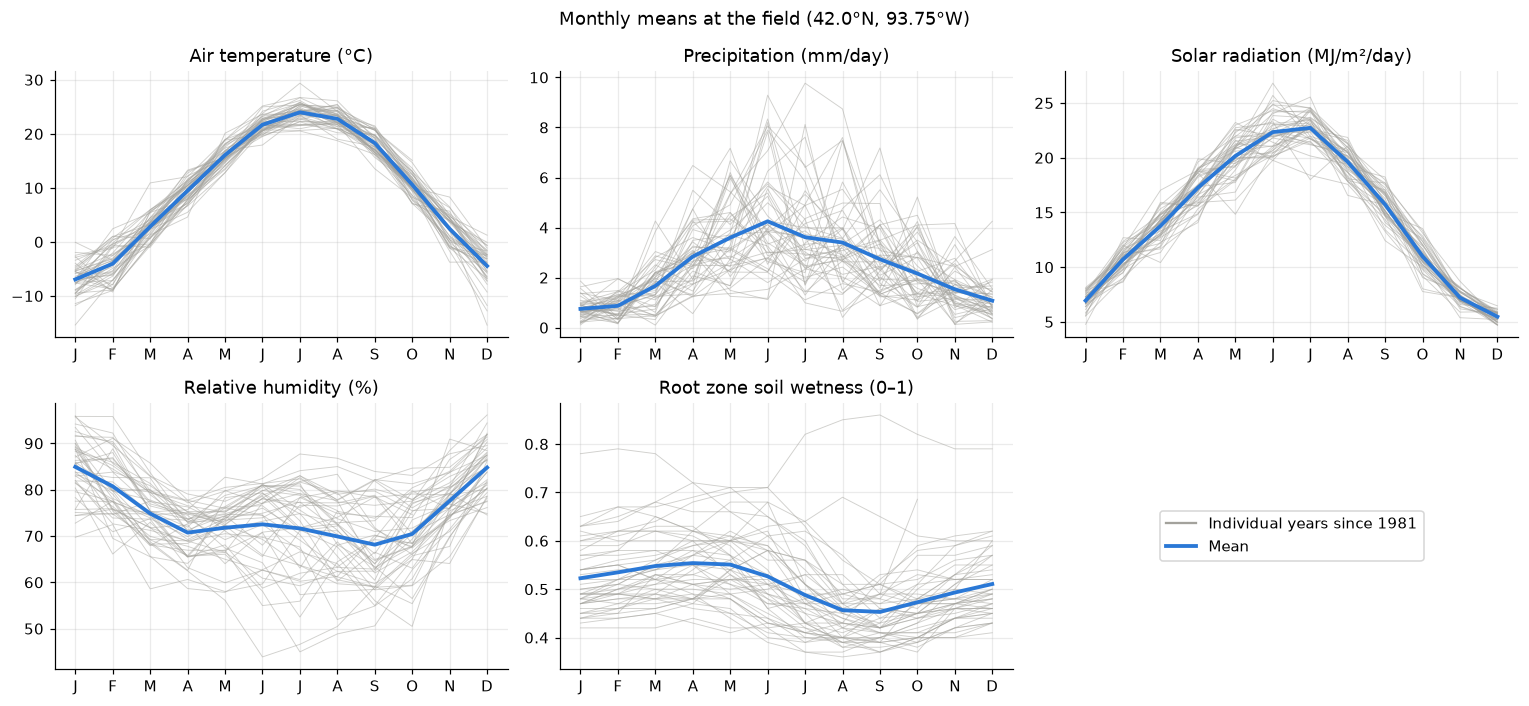

In [5]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#a3a29c'
# Blue = cooler, duller or wetter; orange = warmer, sunnier or drier.
COLORS = {code: (BLUE, ORANGE) if code in ('T2M', 'ALLSKY_SFC_SW_DWN') else (ORANGE, BLUE) for code in TARGETS}

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, (code, (name, units, *_)) in zip(axes.flat, TARGETS.items()):
    series = at_field[code].dropna()
    for _, year in series.groupby(series.index.year):
        ax.plot(year.index.month, year.to_numpy(), color=GRAY, lw=0.6, alpha=0.5)
    ax.plot(series.groupby(series.index.month).mean(), color=BLUE, lw=2.5)
    ax.set(title=f'{name} ({units})', xticks=range(1, 13), xticklabels=list('JFMAMJJASOND'))
    ax.grid(alpha=0.25)
axes.flat[-1].axis('off')
axes.flat[-1].legend(handles=[plt.Line2D([], [], color=GRAY, label='Individual years since 1981'),
                              plt.Line2D([], [], color=BLUE, lw=2.5, label='Mean')], loc='center')
fig.suptitle(f'Monthly means at the field ({center.lat}°N, {-center.lon}°W)')
fig.tight_layout()
plt.show()

## 3. Features and labels

Every row is one grid cell, forecast date and lead, and all its inputs are known on the forecast date. The
label is the category the target month fell in: 0 below, 1 near or 2 above normal. Normals and category
boundaries come only from data before `base_end`, so the backtest never sees the future.

In [6]:
def build(base_end: pd.Timestamp) -> pd.DataFrame:
    """Returns one row per cell, forecast date and lead, with normals from months before `base_end`."""
    panel = power.assign(month=power.time.dt.month)
    base = panel[panel.time < base_end].groupby(['lat', 'lon', 'month'])
    normal = base[VARIABLES].mean()
    bounds = pd.concat([base[list(TARGETS)].quantile(1 / 3).add_prefix('lo_'),
                        base[list(TARGETS)].quantile(2 / 3).add_prefix('hi_')], axis=1)

    expected = normal.reindex(pd.MultiIndex.from_frame(panel[['lat', 'lon', 'month']])).to_numpy()
    anomaly = panel[['lat', 'lon', 'time']].assign(**dict(zip(
        VARIABLES, (panel[VARIABLES].to_numpy() - expected).T)))
    # ORIGIN is not observed yet: an empty row lets shift() carry the last months into it.
    anomaly = pd.concat([anomaly, cells.assign(time=ORIGIN)]).sort_values(
        ['lat', 'lon', 'time'], ignore_index=True)
    by_cell = anomaly.groupby(['lat', 'lon'])[VARIABLES]
    known = pd.concat([  # Known at the start of each month: the last month and the last 3 months.
        anomaly[['lat', 'lon', 'time']].rename(columns={'time': 'origin'}),
        by_cell.shift(1).add_suffix('_last1'),
        by_cell.transform(lambda s: s.rolling(3).mean().shift(1)).add_suffix('_last3'),
    ], axis=1)
    rows = pd.concat([known.assign(lead=lead, target=known.origin + pd.DateOffset(months=lead - 1))
                      for lead in LEADS], ignore_index=True)
    rows['target_month'] = rows.target.dt.month

    values = panel[['lat', 'lon', 'time', *TARGETS]].rename(columns={'time': 'target'})
    rows = rows.merge(values.rename(columns={c: f'v_{c}' for c in TARGETS}), on=['lat', 'lon', 'target'],
                      how='left')
    rows = rows.merge(normal[list(TARGETS)].add_prefix('normal_').join(bounds).reset_index()
                      .rename(columns={'month': 'target_month'}), on=['lat', 'lon', 'target_month'])
    for code in TARGETS:
        value = rows[f'v_{code}']
        rows[f'y_{code}'] = np.where(value.isna(), np.nan, np.select(
            [value < rows[f'lo_{code}'], value <= rows[f'hi_{code}']], [0, 1], 2))
    rows['glat'], rows['glon'] = np.floor(rows.lat + 0.5), np.floor(rows.lon + 0.5)  # nearest 1° node
    rows = rows.merge(geos_features, on=['glat', 'glon', 'origin', 'target'], how='left')
    return rows.drop(columns=['glat', 'glon']).dropna(subset=['T2M_last3'])


def features(rows: pd.DataFrame) -> list[str]:
    return [c for c in rows.columns
            if c not in ('origin', 'target') and not c.startswith(('v_', 'y_', 'lo_', 'hi_'))]


def fit(rows: pd.DataFrame, code: str) -> tuple[HistGradientBoostingClassifier, list[str]]:
    """Fits the below/near/above classifier of one variable on the labelled rows."""
    train = rows[rows[f'y_{code}'].notna()]
    used = [f for f in features(rows) if train[f].notna().any()]  # GEOS-S2S is empty before 2018
    model = HistGradientBoostingClassifier(**HGB_PARAMS)
    return model.fit(train[used], train[f'y_{code}'].astype(int)), used

## 4. Backtest: how sure is the model?

The test covers every forecast date from March 2010 to the latest complete month, at leads 1–12, scored
against what actually happened.

In [7]:
started = time.perf_counter()
scored = []
for year in range(FIRST_FOLD, ORIGIN.year + 1, FOLD_YEARS):
    start = pd.Timestamp(year, 3, 1)
    end = min(start + pd.DateOffset(years=FOLD_YEARS), ORIGIN)
    if start >= ORIGIN:
        break
    rows = build(start)
    test = rows[(rows.origin >= start) & (rows.origin < end)]
    for code in TARGETS:
        model, used = fit(rows[rows.target < start], code)
        observed = test[test[f'y_{code}'].notna()]
        p = model.predict_proba(observed[used])
        scored.append(pd.DataFrame({
            'code': code, 'origin': observed.origin.to_numpy(), 'lead': observed.lead.to_numpy(),
            'y': observed[f'y_{code}'].to_numpy(), 'p0': p[:, 0], 'p1': p[:, 1], 'p2': p[:, 2]}))
    print(f'{start.date()} … {end.date()}: {time.perf_counter() - started:.0f} s')
scored = pd.concat(scored, ignore_index=True)

# Ranked probability score: squared error of the cumulative probabilities; 33/33/33 is the reference.
below, not_above = (scored.y == 0).astype(float), (scored.y <= 1).astype(float)
scored['rps'] = (scored.p0 - below) ** 2 + (scored.p0 + scored.p1 - not_above) ** 2
scored['rps_ref'] = (1 / 3 - below) ** 2 + (2 / 3 - not_above) ** 2
scored['hit'] = scored[['p0', 'p1', 'p2']].to_numpy().argmax(axis=1) == scored.y
scored['half'] = np.where(scored.origin < pd.Timestamp(SPLIT_YEAR, 3, 1), 'first', 'second')


def skill(frame: pd.DataFrame) -> pd.Series:
    return 1 - frame.rps.mean() / frame.rps_ref.mean()


record = scored.groupby(['code', 'lead']).apply(lambda g: pd.Series({
    'skill': skill(g),
    'skill_first_half': skill(g[g.half == 'first']),
    'skill_second_half': skill(g[g.half == 'second']),
    'hit_rate': g.hit.mean(),
}))
record['shown'] = ((record[['skill_first_half', 'skill_second_half']].min(axis=1) > 0)
                   & (record.skill >= MIN_SKILL))
record['confidence'] = np.where(~record.shown, 'no signal', pd.cut(
    record.skill, [-np.inf, 0.1, 0.25, np.inf], labels=['low', 'moderate', 'high']).astype(str))
record.round(3)

2010-03-01 … 2012-03-01: 16 s


2012-03-01 … 2014-03-01: 32 s


2014-03-01 … 2016-03-01: 48 s


2016-03-01 … 2018-03-01: 65 s


2018-03-01 … 2020-03-01: 84 s


2020-03-01 … 2022-03-01: 104 s


2022-03-01 … 2024-03-01: 125 s


2024-03-01 … 2026-03-01: 148 s


2026-03-01 … 2026-11-01: 172 s


skill  skill_first_half  skill_second_half  hit_rate  \
code              lead                                                         
ALLSKY_SFC_SW_DWN 1    -0.021            -0.003             -0.036     0.332   
                  2    -0.023            -0.013             -0.033     0.335   
                  3    -0.027            -0.009             -0.043     0.338   
                  4    -0.032            -0.003             -0.059     0.343   
                  5    -0.033            -0.010             -0.054     0.331   
                  6    -0.014            -0.005             -0.024     0.358   
                  7    -0.023            -0.005             -0.041     0.343   
                  8    -0.029            -0.007             -0.050     0.343   
                  9    -0.003            -0.006             -0.001     0.363   
                  10    0.000            -0.006              0.007     0.348   
                  11   -0.006            -0.016              0.005     0.335   
                  12   -0.010            -0.019             -0.000     0.334   
GWETROOT          1     0.425             0.469              0.384     0.698   
                  2     0.297             0.333              0.263     0.598   
                  3     0.189             0.232              0.148     0.537   
                  4     0.115             0.169              0.064     0.496   
                  5     0.066             0.126              0.008     0.473   
                  6     0.026             0.085             -0.030     0.456   
                  7    -0.019             0.040             -0.076     0.426   
                  8    -0.061            -0.013             -0.108     0.411   
                  9     0.044            -0.056              0.144     0.440   
                  10    0.031            -0.074              0.136     0.434   
                  11    0.026            -0.079              0.132     0.424   
                  12    0.032            -0.071              0.139     0.418   
PRECTOTCORR       1    -0.033             0.005             -0.067     0.332   
                  2    -0.036             0.003             -0.071     0.322   
                  3    -0.034            -0.003             -0.063     0.329   
                  4    -0.039            -0.000             -0.076     0.330   
                  5    -0.045            -0.007             -0.081     0.318   
                  6    -0.038            -0.003             -0.072     0.322   
                  7    -0.035            -0.015             -0.055     0.328   
                  8    -0.048            -0.020             -0.075     0.319   
                  9    -0.006            -0.017              0.005     0.346   
                  10    0.001            -0.004              0.007     0.366   
                  11    0.006             0.003              0.008     0.366   
                  12    0.006             0.004              0.008     0.357   
RH2M              1     0.232             0.273              0.196     0.581   
                  2     0.146             0.178              0.118     0.520   
                  3     0.085             0.121              0.052     0.500   
                  4     0.046             0.081              0.014     0.476   
                  5     0.016             0.046             -0.011     0.461   
                  6    -0.003             0.043             -0.045     0.450   
                  7    -0.023             0.021             -0.064     0.435   
                  8    -0.045            -0.011             -0.077     0.420   
                  9     0.049            -0.037              0.132     0.455   
                  10    0.052            -0.035              0.137     0.454   
                  11    0.046            -0.044              0.136     0.441   
                  12    0.057            -0.035              0.150     0.445   
T2M               1     

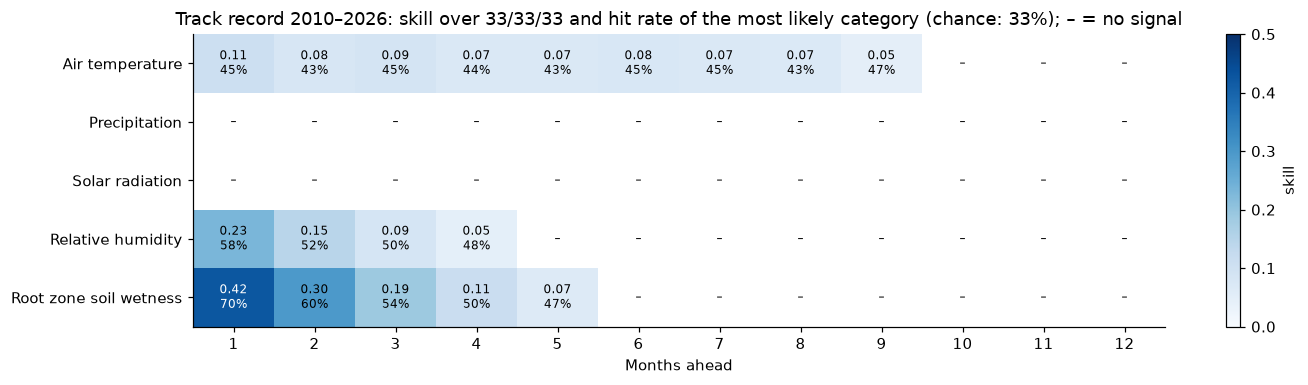

In [8]:
shown_skill = record.skill.where(record.shown).unstack('lead').reindex(list(TARGETS))
fig, ax = plt.subplots(figsize=(13, 3.6))
image = ax.imshow(shown_skill.clip(lower=0), cmap='Blues', vmin=0, vmax=0.5, aspect='auto')
for (i, code), (j, lead) in ((a, b) for a in enumerate(shown_skill.index) for b in enumerate(LEADS)):
    row = record.loc[(code, lead)]
    text = f'{row.skill:.2f}\n{row.hit_rate:.0%}' if row.shown else '–'
    ax.text(j, i, text, ha='center', va='center', fontsize=8,
            color='white' if row.shown and row.skill > 0.3 else 'black')
ax.set_xticks(range(len(LEADS)), [f'{lead}' for lead in LEADS])
ax.set_yticks(range(len(TARGETS)), [TARGETS[c][0] for c in shown_skill.index])
ax.set_xlabel('Months ahead')
ax.set_title('Track record 2010–2026: skill over 33/33/33 and hit rate of the most likely category '
             '(chance: 33%); – = no signal')
fig.colorbar(image, ax=ax, label='skill')
fig.tight_layout()
plt.show()

**Are the percentages honest?** When the outlook says "60%", that category should happen about 60% of the
time. The chart below groups all shown forecasts by their stated probability and plots how often the
category really happened. Points near the diagonal mean the percentages can be taken at face value.

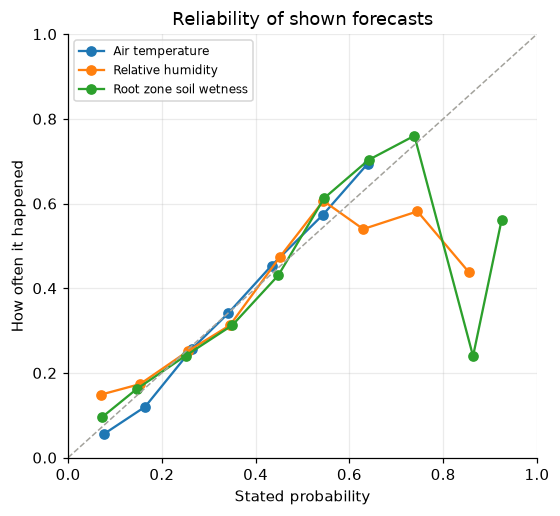

In [9]:
used_scores = scored.join(record.shown, on=['code', 'lead'])
used_scores = used_scores[used_scores.shown]
fig, ax = plt.subplots(figsize=(5.5, 5))
bins = np.linspace(0, 1, 11)
for code in used_scores.code.unique():
    s = used_scores[used_scores.code == code]
    stated = np.concatenate([s.p0, s.p1, s.p2])
    happened = np.concatenate([s.y == 0, s.y == 1, s.y == 2])
    group = pd.cut(stated, bins)
    table = pd.DataFrame({'stated': stated, 'happened': happened, 'bin': group}).groupby(
        'bin', observed=True).agg(stated=('stated', 'mean'), happened=('happened', 'mean'),
                                  n=('stated', 'size'))
    table = table[table.n >= 500]  # fewer cases are too noisy to judge
    ax.plot(table.stated, table.happened, marker='o', label=TARGETS[code][0])
ax.plot([0, 1], [0, 1], color=GRAY, ls='--', lw=1)
ax.set(xlabel='Stated probability', ylabel='How often it happened', xlim=(0, 1), ylim=(0, 1),
       title='Reliability of shown forecasts')
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
plt.show()

## 5. The outlook

The final models are trained on every labelled month before the forecast date. Where the track record
shows no signal, the probabilities are replaced by 33/33/33.

In [10]:
started = time.perf_counter()
rows = build(ORIGIN)
now = rows[(rows.origin == ORIGIN) & (rows.lat == center.lat) & (rows.lon == center.lon)].sort_values('lead')
outlook = []
for code, (name, units, below_word, above_word) in TARGETS.items():
    model, used = fit(rows[rows.target < ORIGIN], code)
    p = model.predict_proba(now[used])
    for (_, row), probabilities in zip(now.iterrows(), p):
        track = record.loc[(code, row.lead)]
        if not track.shown:
            probabilities = np.full(3, 1 / 3)
        outlook.append({
            'variable': name, 'month': row.target.strftime('%Y-%m'), 'lead': row.lead,
            'normal range': f'{row[f"lo_{code}"]:.3g} – {row[f"hi_{code}"]:.3g} {units}',
            'below': probabilities[0], 'near': probabilities[1], 'above': probabilities[2],
            'below / above means': f'{below_word} / {above_word}',
            'confidence': track.confidence,
            'past hit rate': track.hit_rate if track.shown else np.nan,
            'code': code,
        })
outlook = pd.DataFrame(outlook)
print(f'Trained the final models in {time.perf_counter() - started:.0f} s; forecast date {ORIGIN.date()}')

Trained the final models in 24 s; forecast date 2026-11-01


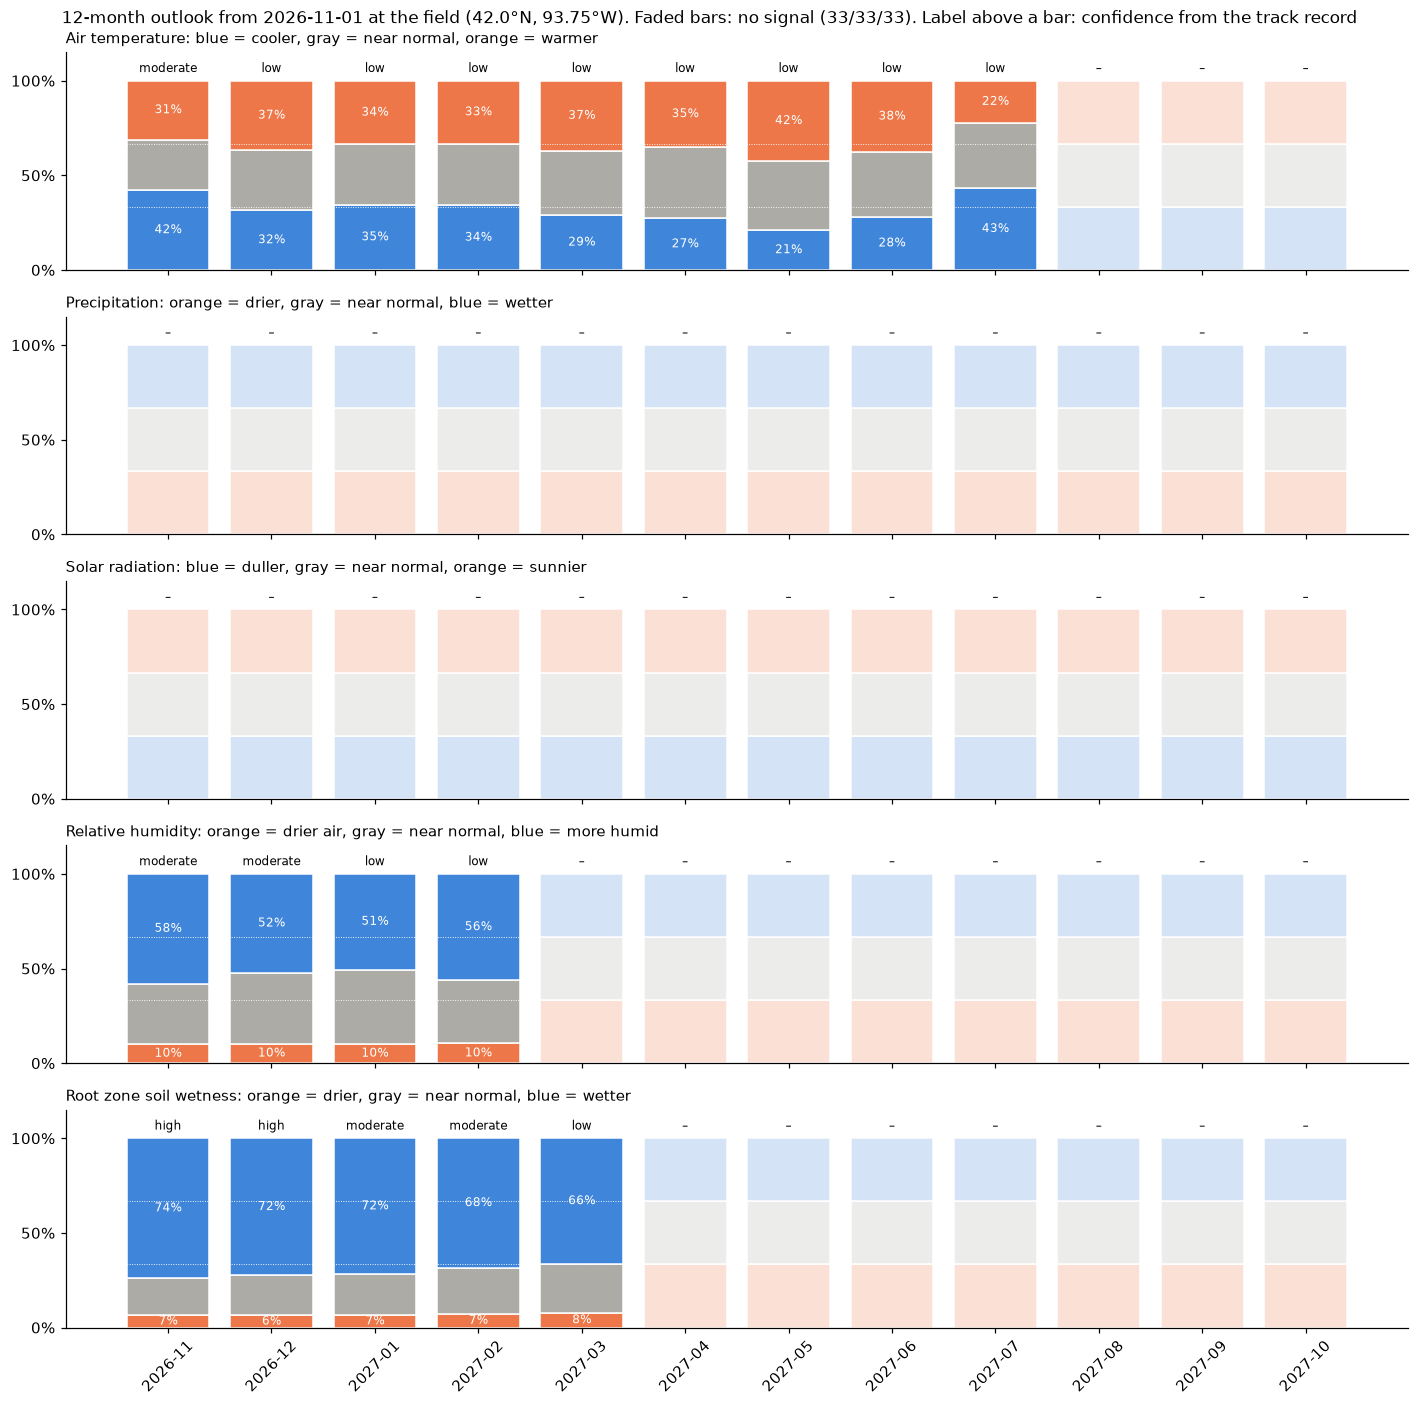

In [11]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(13, 13), sharex=True)
months = outlook.month.unique()
for ax, (code, (name, units, below_word, above_word)) in zip(axes, TARGETS.items()):
    part = outlook[outlook.code == code]
    p = part[['below', 'near', 'above']].to_numpy().T
    shown = (part.confidence != 'no signal').to_numpy()
    below_color, above_color = COLORS[code]
    x = np.arange(len(part))
    for bottom, height, color in ((0, p[0], below_color), (p[0], p[1], GRAY), (p[0] + p[1], p[2], above_color)):
        ax.bar(x, height, bottom=bottom, width=0.8, edgecolor='white', linewidth=1,
               color=[to_rgba(color, 0.9 if s else 0.2) for s in shown])
    for xi, (pb, pa, conf) in enumerate(zip(p[0], p[2], part.confidence)):
        if conf != 'no signal':
            ax.text(xi, pb / 2, f'{pb:.0%}', ha='center', va='center', fontsize=8, color='white')
            ax.text(xi, 1 - pa / 2, f'{pa:.0%}', ha='center', va='center', fontsize=8, color='white')
        ax.text(xi, 1.03, conf if conf != 'no signal' else '–', ha='center', va='bottom', fontsize=8)
    ax.axhline(1 / 3, color='white', lw=0.6, ls=':')
    ax.axhline(2 / 3, color='white', lw=0.6, ls=':')
    ax.set(ylim=(0, 1.15), yticks=[0, 0.5, 1], yticklabels=['0%', '50%', '100%'])
    color_name = {BLUE: 'blue', ORANGE: 'orange'}
    ax.set_title(f'{name}: {color_name[below_color]} = {below_word}, gray = near normal, '
                 f'{color_name[above_color]} = {above_word}', fontsize=10, loc='left')
axes[-1].set_xticks(range(len(months)), months, rotation=45)
fig.suptitle(f'12-month outlook from {ORIGIN.date()} at the field ({center.lat}°N, {-center.lon}°W). '
             'Faded bars: no signal (33/33/33). Label above a bar: confidence from the track record',
             fontsize=11)
fig.tight_layout()
plt.show()

In [12]:
table = outlook.drop(columns=['code', 'lead']).set_index(['variable', 'month'])
for column in ['below', 'near', 'above', 'past hit rate']:
    table[column] = table[column].map(lambda v: '–' if np.isnan(v) else f'{v:.0%}')
pd.set_option('display.max_rows', 100)
table

normal range below near above  \
variable               month                                             
Air temperature        2026-11         1.09 – 3.97 °C   42%  27%   31%   
                       2026-12       -5.04 – -2.75 °C   32%  32%   37%   
                       2027-01       -7.76 – -5.51 °C   35%  32%   34%   
                       2027-02       -5.85 – -2.51 °C   34%  33%   33%   
                       2027-03         2.23 – 3.65 °C   29%  34%   37%   
                       2027-04         8.47 – 10.5 °C   27%  37%   35%   
                       2027-05         15.4 – 16.7 °C   21%  37%   42%   
                       2027-06         20.9 – 22.4 °C   28%  34%   38%   
                       2027-07         23.4 – 24.7 °C   43%  34%   22%   
                       2027-08           22 – 23.6 °C   33%  33%   33%   
                       2027-09         17.1 – 19.3 °C   33%  33%   33%   
                       2027-10         9.88 – 11.3 °C   33%  33%   33%   
Precipitation          2026-11     1.15 – 1.74 mm/day   33%  33%   33%   
                       2026-12    0.743 – 1.16 mm/day   33%  33%   33%   
                       2027-01     0.58 – 0.88 mm/day   33%  33%   33%   
                       2027-02     0.55 – 1.09 mm/day   33%  33%   33%   
                       2027-03     1.25 – 2.02 mm/day   33%  33%   33%   
                       2027-04     2.36 – 3.09 mm/day   33%  33%   33%   
                       2027-05     2.74 – 4.12 mm/day   33%  33%   33%   
                       2027-06     3.02 – 4.46 mm/day   33%  33%   33%   
                       2027-07     2.65 – 3.99 mm/day   33%  33%   33%   
                       2027-08     2.69 – 3.57 mm/day   33%  33%   33%   
                       2027-09     1.94 – 3.17 mm/day   33%  33%   33%   
                       2027-10     1.37 – 2.79 mm/day   33%  33%   33%   
Solar radiation        2026-11  6.96 – 7.43 MJ/m²/day   33%  33%   33%   
                       2026-12  5.23 – 5.77 MJ/m²/day   33%  33%   33%   
                       2027-01  6.68 – 7.28 MJ/m²/day   33%  33%   33%   
                       2027-02  10.3 – 11.2 MJ/m²/day   33%  33%   33%   
                       2027-03  13.1 – 14.4 MJ/m²/day   33%  33%   33%   
                       2027-04  16.6 – 18.4 MJ/m²/day   33%  33%   33%   
                       2027-05  19.6 – 21.1 MJ/m²/day   33%  33%   33%   
                       2027-06    21.4 – 23 MJ/m²/day   33%  33%   33%   
                       2027-07  22.4 – 23.4 MJ/m²/day   33%  33%   33%   
                       2027-08  19.1 – 20.4 MJ/m²/day   33%  33%   33%   
                       2027-09  15.1 – 16.5 MJ/m²/day   33%  33%   33%   
                       2027-10  10.5 – 11.5 MJ/m²/day   33%  33%   33%   
Relative humidity      2026-11          75.2 – 79.5 %   10%  32%   58%   
                       2026-12          81.5 – 87.5 %   10%  37%   52%   
                       2027-01            83 – 88.7 %   10%  39%   51%   
                       2027-02          77.3 – 83.9 %   10%  33%   56%   
                       2027-03            73 – 77.5 %   33%  33%   33%   
                       2027-04          68.9 – 73.7 %   33%  33%   33%   
                       2027-05          71.1 – 74.7 %   33%  33%   33%   
                       2027-06          70.8 – 78.2 %   33%  33%   33%   
                       2027-07          69.1 – 78.3 %   33%  33%   33%   
                       2027-08          65.6 – 74.9 %   33%  33%   33%   
                       2027-09          62.9 – 71.8 %   33%  33%   33%   
                       2027-10          67.7 – 75.3 %   33%  33%   33%   
Root zone soil wetness 2026-11        0.46 – 0.51 0–1    7%  19%   74%   
                       2026-12       0.47 – 0.523 0–1    6%  21%   72%   
                       2027-01        0.48 – 0.54 0–1    7%  21%   72%   
                       2027-02        0.49 – 0.55 0–1    7%  24%   68%   
                       2027-03        0.51 – 

## Notes

- **How to read it:** the bars give the chance of each category, and the label above each bar gives the
  confidence from the track record. *No signal* means the model has not beaten plain 33/33/33 at that lead in
  past years, so the best guess is a normal month.
- **What the track record shows:** root zone soil wetness and humidity are forecastable for the first few
  months, because soil and air moisture change slowly. Temperature carries a small but steady signal up to
  about 9 months ahead, roughly as far as GEOS-S2S reaches. Part of it is the warming trend: recent months fall in the
  "above" third of the 1981–present range more often than 1 in 3. Precipitation and solar radiation show no
  signal at any lead.
- **Very confident forecasts are rare and less reliable.** Up to about 70%, stated chances matched how
  often things happened. Above that, soil wetness and humidity have been overconfident. Read "85%" as
  "likely", not "almost certain".
- **"Normal" moves:** categories are relative to all years since 1981. In a warming climate, "near normal"
  temperature is already warmer than it was in the 1980s.
- **Speed:** the backtest (9 refits) takes ~3 minutes on a laptop CPU and the final fit ~25 s. Raise
  `FOLD_YEARS` or shrink `BBOX` on weaker hardware.
- **Next steps:** add the NMME multi-model mean (`ag.NMME(http).area(..., model='NMME')`) as a second
  forecast source, and turn the outlook into crop terms (planting-time soil moisture, July drought risk).